In [1]:
import numpy as np
import matplotlib.pyplot as plt 

import pandas as pd  
import seaborn as sns 
from sklearn import metrics
import scipy.io as sio
%matplotlib inline
from sklearn.model_selection import train_test_split
from sklearn import preprocessing
import warnings
warnings.filterwarnings('ignore')
import xarray as xr
from sklearn.preprocessing import PolynomialFeatures

In [2]:
import cartopy.crs as ccrs
import cartopy.feature as cf
import cartopy.io.shapereader

# IMD Data (Observations) 

## Week 1

In [3]:
## training data

week = '1'

file_path_obs_train = f'IMD_Data/Week{week}/IMD_pra_1989-2010.nc'
file_path_model_train = f'IMD_Data/Week{week}/GEFS_pra_1989-2010.nc'
data_obs_train = xr.open_dataset(file_path_obs_train)
data_model_train = xr.open_dataset(file_path_model_train)

## test data

file_path_obs_test = f'IMD_Data/Week{week}/IMD_pra_2011-2018.nc'
file_path_model_test = f'IMD_Data/Week{week}/GEFS_pra_2011-2018.nc'
data_obs_test = xr.open_dataset(file_path_obs_test)
data_model_test = xr.open_dataset(file_path_model_test)

In [4]:
def count_missing(grid):
    return np.count_nonzero(~np.isnan(grid), axis=0)

In [5]:
def count_nonzero(grid):
    return np.count_nonzero(grid, axis=0)

In [6]:
missing_mat = count_missing(data_obs_train['prcp'].values)

In [7]:
nonz_mat = count_nonzero(data_obs_train['prcp'].values)

In [8]:
threshold = 0.30
indices = np.argwhere((386-nonz_mat)/386>threshold)

In [9]:
nonz_mat.shape

(32, 31)

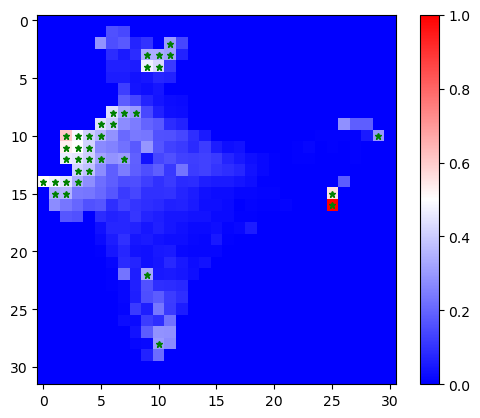

In [10]:
plt.imshow(np.flip((386-nonz_mat)/386, axis=0), cmap='bwr')

# Plot red asterisks on the indices
for index in indices:
    plt.plot(index[1], 31-index[0], 'g*', markersize=5)

plt.colorbar()

In [11]:
def plot(ax, west, east, south, north):
    """
    Add geographical boundaries from the shapes folder to the plot.

    Parameters:
        - ax (matplotlib.axes._subplots.AxesSubplot): Axes object to add geographical boundaries.
        - west, east, south, north (float): Geographic bounds for the region of interest.
    """
    for shape_name in 'indian_borders', 'sd_boundary':
        reader = cartopy.io.shapereader.Reader(f'shapes/{shape_name}')
        ax.add_geometries(reader.geometries(), ccrs.PlateCarree(), facecolor='none')

In [12]:
threshold = 0.30
indices = np.argwhere((140-nonz_mat)/140>threshold)

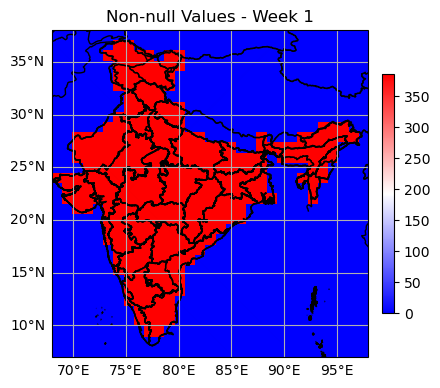

In [13]:
west, east, south, north = 68, 98, 7, 38
fig = plt.figure(figsize=(15,5))

# Plot for RPSS
ax1 = fig.add_subplot(1, 3, 1, projection=ccrs.PlateCarree())
ax1.set_extent([west, east, south, north], crs=ccrs.PlateCarree())
rpss_image = ax1.imshow(np.flip(missing_mat, axis=0), cmap='bwr', extent=[west, east, south, north])
ax1.set_title(f"Non-null Values - Week {week}")
ax1.add_feature(cf.BORDERS)
ax1.add_feature(cf.STATES)
gl = ax1.gridlines(draw_labels=True)
gl.top_labels = False
gl.right_labels = False
plt.colorbar(rpss_image, ax=ax1, fraction=0.035, pad=0.04)

plot(ax1, west, east, south, north)

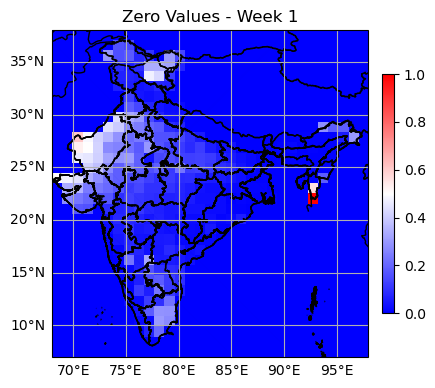

In [14]:
west, east, south, north = 68, 98, 7, 38
fig = plt.figure(figsize=(15,5))

# Plot for RPSS
ax1 = fig.add_subplot(1, 3, 1, projection=ccrs.PlateCarree())
ax1.set_extent([west, east, south, north], crs=ccrs.PlateCarree())
rpss_image = ax1.imshow(np.flip((386-nonz_mat)/386, axis=0), cmap='bwr', extent=[west, east, south, north])
ax1.set_title(f"Zero Values - Week {week}")
ax1.add_feature(cf.BORDERS)
ax1.add_feature(cf.STATES)
gl = ax1.gridlines(draw_labels=True)
gl.top_labels = False
gl.right_labels = False
plt.colorbar(rpss_image, ax=ax1, fraction=0.035, pad=0.04)

plot(ax1, west, east, south, north)

## Week 2 

In [15]:
## training data

week = '2'

file_path_obs_train = f'IMD_Data/Week{week}/IMD_pra_1989-2010.nc'
file_path_model_train = f'IMD_Data/Week{week}/GEFS_pra_1989-2010.nc'
data_obs_train = xr.open_dataset(file_path_obs_train)
data_model_train = xr.open_dataset(file_path_model_train)

## test data

file_path_obs_test = f'IMD_Data/Week{week}/IMD_pra_2011-2018.nc'
file_path_model_test = f'IMD_Data/Week{week}/GEFS_pra_2011-2018.nc'
data_obs_test = xr.open_dataset(file_path_obs_test)
data_model_test = xr.open_dataset(file_path_model_test)

In [16]:
missing_mat = count_missing(data_obs_train['prcp'].values)
nonz_mat = count_nonzero(data_obs_train['prcp'].values)

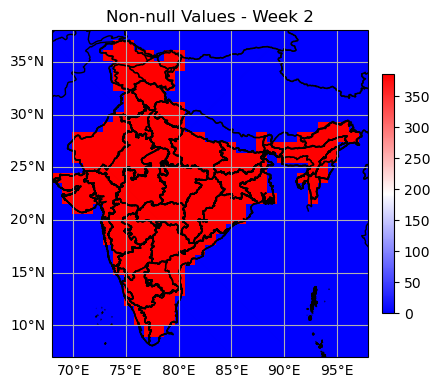

In [17]:
west, east, south, north = 68, 98, 7, 38
fig = plt.figure(figsize=(15,5))

# Plot for RPSS
ax1 = fig.add_subplot(1, 3, 1, projection=ccrs.PlateCarree())
ax1.set_extent([west, east, south, north], crs=ccrs.PlateCarree())
rpss_image = ax1.imshow(np.flip(missing_mat, axis=0), cmap='bwr', extent=[west, east, south, north])
ax1.set_title(f"Non-null Values - Week {week}")
ax1.add_feature(cf.BORDERS)
ax1.add_feature(cf.STATES)
gl = ax1.gridlines(draw_labels=True)
gl.top_labels = False
gl.right_labels = False
plt.colorbar(rpss_image, ax=ax1, fraction=0.035, pad=0.04)

plot(ax1, west, east, south, north)

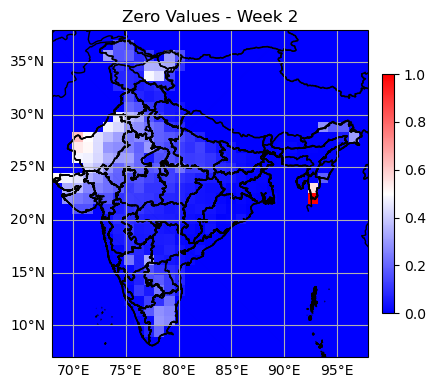

In [18]:
west, east, south, north = 68, 98, 7, 38
fig = plt.figure(figsize=(15,5))

# Plot for RPSS
ax1 = fig.add_subplot(1, 3, 1, projection=ccrs.PlateCarree())
ax1.set_extent([west, east, south, north], crs=ccrs.PlateCarree())
rpss_image = ax1.imshow(np.flip((386-nonz_mat)/386, axis=0), cmap='bwr', extent=[west, east, south, north])
ax1.set_title(f"Zero Values - Week {week}")
ax1.add_feature(cf.BORDERS)
ax1.add_feature(cf.STATES)
gl = ax1.gridlines(draw_labels=True)
gl.top_labels = False
gl.right_labels = False
plt.colorbar(rpss_image, ax=ax1, fraction=0.035, pad=0.04)

plot(ax1, west, east, south, north)

## Weeks 3&4 

In [19]:
## training data

week = '34'

file_path_obs_train = f'IMD_Data/Week{week}/IMD_pra_1989-2010.nc'
file_path_model_train = f'IMD_Data/Week{week}/GEFS_pra_1989-2010.nc'
data_obs_train = xr.open_dataset(file_path_obs_train)
data_model_train = xr.open_dataset(file_path_model_train)

## test data

file_path_obs_test = f'IMD_Data/Week{week}/IMD_pra_2011-2018.nc'
file_path_model_test = f'IMD_Data/Week{week}/GEFS_pra_2011-2018.nc'
data_obs_test = xr.open_dataset(file_path_obs_test)
data_model_test = xr.open_dataset(file_path_model_test)

In [20]:
missing_mat = count_missing(data_obs_train['prcp'].values)
nonz_mat = count_nonzero(data_obs_train['prcp'].values)

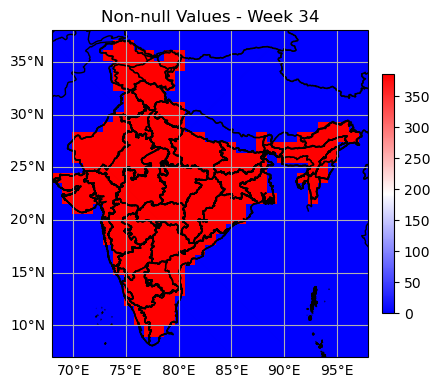

In [21]:
west, east, south, north = 68, 98, 7, 38
fig = plt.figure(figsize=(15,5))

# Plot for RPSS
ax1 = fig.add_subplot(1, 3, 1, projection=ccrs.PlateCarree())
ax1.set_extent([west, east, south, north], crs=ccrs.PlateCarree())
rpss_image = ax1.imshow(np.flip(missing_mat, axis=0), cmap='bwr', extent=[west, east, south, north])
ax1.set_title(f"Non-null Values - Week {week}")
ax1.add_feature(cf.BORDERS)
ax1.add_feature(cf.STATES)
gl = ax1.gridlines(draw_labels=True)
gl.top_labels = False
gl.right_labels = False
plt.colorbar(rpss_image, ax=ax1, fraction=0.035, pad=0.04)

plot(ax1, west, east, south, north)

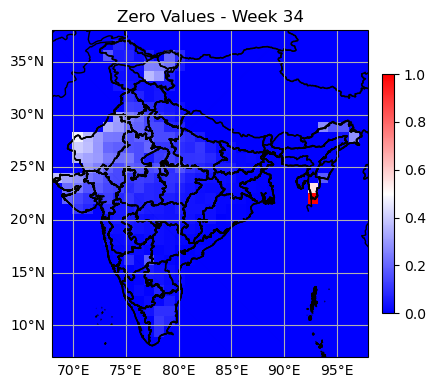

In [22]:
west, east, south, north = 68, 98, 7, 38
fig = plt.figure(figsize=(15,5))

# Plot for RPSS
ax1 = fig.add_subplot(1, 3, 1, projection=ccrs.PlateCarree())
ax1.set_extent([west, east, south, north], crs=ccrs.PlateCarree())
rpss_image = ax1.imshow(np.flip((386-nonz_mat)/386, axis=0), cmap='bwr', extent=[west, east, south, north])
ax1.set_title(f"Zero Values - Week {week}")
ax1.add_feature(cf.BORDERS)
ax1.add_feature(cf.STATES)
gl = ax1.gridlines(draw_labels=True)
gl.top_labels = False
gl.right_labels = False
plt.colorbar(rpss_image, ax=ax1, fraction=0.035, pad=0.04)

plot(ax1, west, east, south, north)

# IMD - Test Data

## Week 1 

In [23]:
## training data

week = '1'

file_path_obs_train = f'IMD_Data/Week{week}/IMD_pra_1989-2010.nc'
file_path_model_train = f'IMD_Data/Week{week}/GEFS_pra_1989-2010.nc'
data_obs_train = xr.open_dataset(file_path_obs_train)
data_model_train = xr.open_dataset(file_path_model_train)

## test data

file_path_obs_test = f'IMD_Data/Week{week}/IMD_pra_2011-2018.nc'
file_path_model_test = f'IMD_Data/Week{week}/GEFS_pra_2011-2018.nc'
data_obs_test = xr.open_dataset(file_path_obs_test)
data_model_test = xr.open_dataset(file_path_model_test)

In [24]:
missing_mat = count_missing(data_obs_test['prcp'].values)
nonz_mat = count_nonzero(data_obs_test['prcp'].values)

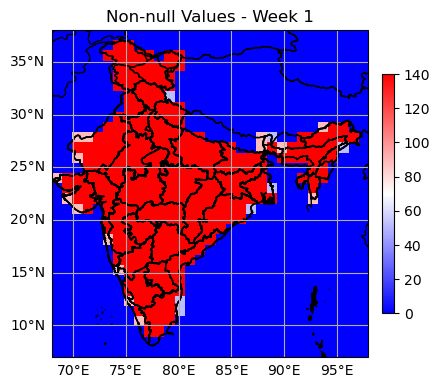

In [25]:
west, east, south, north = 68, 98, 7, 38
fig = plt.figure(figsize=(15,5))

# Plot for RPSS
ax1 = fig.add_subplot(1, 3, 1, projection=ccrs.PlateCarree())
ax1.set_extent([west, east, south, north], crs=ccrs.PlateCarree())
rpss_image = ax1.imshow(np.flip(missing_mat, axis=0), cmap='bwr', extent=[west, east, south, north])
ax1.set_title(f"Non-null Values - Week {week}")
ax1.add_feature(cf.BORDERS)
ax1.add_feature(cf.STATES)
gl = ax1.gridlines(draw_labels=True)
gl.top_labels = False
gl.right_labels = False
plt.colorbar(rpss_image, ax=ax1, fraction=0.035, pad=0.04)

plot(ax1, west, east, south, north)

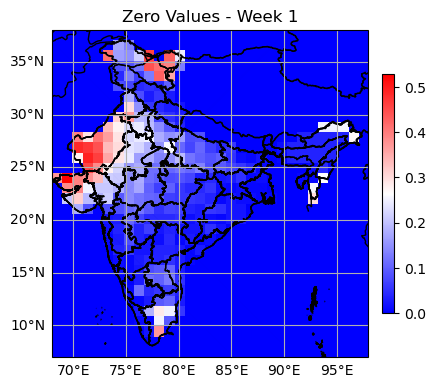

In [26]:
west, east, south, north = 68, 98, 7, 38
fig = plt.figure(figsize=(15,5))

# Plot for RPSS
ax1 = fig.add_subplot(1, 3, 1, projection=ccrs.PlateCarree())
ax1.set_extent([west, east, south, north], crs=ccrs.PlateCarree())
rpss_image = ax1.imshow(np.flip((140-nonz_mat)/140, axis=0), cmap='bwr', extent=[west, east, south, north])
ax1.set_title(f"Zero Values - Week {week}")
ax1.add_feature(cf.BORDERS)
ax1.add_feature(cf.STATES)
gl = ax1.gridlines(draw_labels=True)
gl.top_labels = False
gl.right_labels = False
plt.colorbar(rpss_image, ax=ax1, fraction=0.035, pad=0.04)

plot(ax1, west, east, south, north)

## Week 2 

In [27]:
## training data

week = '2'

file_path_obs_train = f'IMD_Data/Week{week}/IMD_pra_1989-2010.nc'
file_path_model_train = f'IMD_Data/Week{week}/GEFS_pra_1989-2010.nc'
data_obs_train = xr.open_dataset(file_path_obs_train)
data_model_train = xr.open_dataset(file_path_model_train)

## test data

file_path_obs_test = f'IMD_Data/Week{week}/IMD_pra_2011-2018.nc'
file_path_model_test = f'IMD_Data/Week{week}/GEFS_pra_2011-2018.nc'
data_obs_test = xr.open_dataset(file_path_obs_test)
data_model_test = xr.open_dataset(file_path_model_test)

In [28]:
missing_mat = count_missing(data_obs_test['prcp'].values)
nonz_mat = count_nonzero(data_obs_test['prcp'].values)

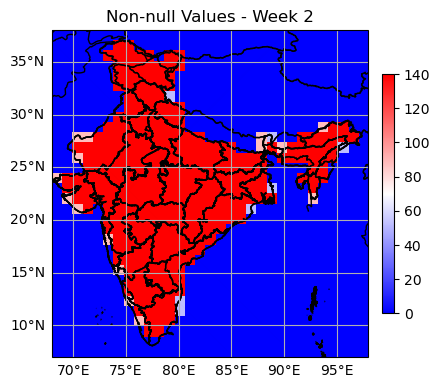

In [29]:
west, east, south, north = 68, 98, 7, 38
fig = plt.figure(figsize=(15,5))

# Plot for RPSS
ax1 = fig.add_subplot(1, 3, 1, projection=ccrs.PlateCarree())
ax1.set_extent([west, east, south, north], crs=ccrs.PlateCarree())
rpss_image = ax1.imshow(np.flip(missing_mat, axis=0), cmap='bwr', extent=[west, east, south, north])
ax1.set_title(f"Non-null Values - Week {week}")
ax1.add_feature(cf.BORDERS)
ax1.add_feature(cf.STATES)
gl = ax1.gridlines(draw_labels=True)
gl.top_labels = False
gl.right_labels = False
plt.colorbar(rpss_image, ax=ax1, fraction=0.035, pad=0.04)

plot(ax1, west, east, south, north)

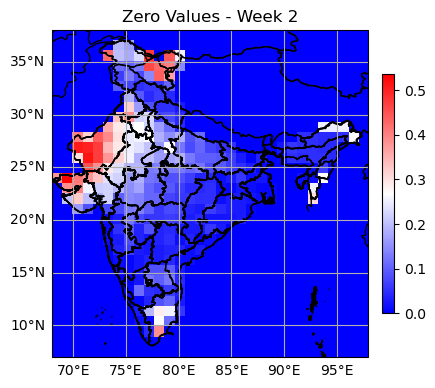

In [30]:
west, east, south, north = 68, 98, 7, 38
fig = plt.figure(figsize=(15,5))

# Plot for RPSS
ax1 = fig.add_subplot(1, 3, 1, projection=ccrs.PlateCarree())
ax1.set_extent([west, east, south, north], crs=ccrs.PlateCarree())
rpss_image = ax1.imshow(np.flip((140-nonz_mat)/140, axis=0), cmap='bwr', extent=[west, east, south, north])
ax1.set_title(f"Zero Values - Week {week}")
ax1.add_feature(cf.BORDERS)
ax1.add_feature(cf.STATES)
gl = ax1.gridlines(draw_labels=True)
gl.top_labels = False
gl.right_labels = False
plt.colorbar(rpss_image, ax=ax1, fraction=0.035, pad=0.04)

plot(ax1, west, east, south, north)

## Weeks 3&4 

In [31]:
## training data

week = '34'

file_path_obs_train = f'IMD_Data/Week{week}/IMD_pra_1989-2010.nc'
file_path_model_train = f'IMD_Data/Week{week}/GEFS_pra_1989-2010.nc'
data_obs_train = xr.open_dataset(file_path_obs_train)
data_model_train = xr.open_dataset(file_path_model_train)

## test data

file_path_obs_test = f'IMD_Data/Week{week}/IMD_pra_2011-2018.nc'
file_path_model_test = f'IMD_Data/Week{week}/GEFS_pra_2011-2018.nc'
data_obs_test = xr.open_dataset(file_path_obs_test)
data_model_test = xr.open_dataset(file_path_model_test)

In [32]:
missing_mat = count_missing(data_obs_test['prcp'].values)
nonz_mat = count_nonzero(data_obs_test['prcp'].values)

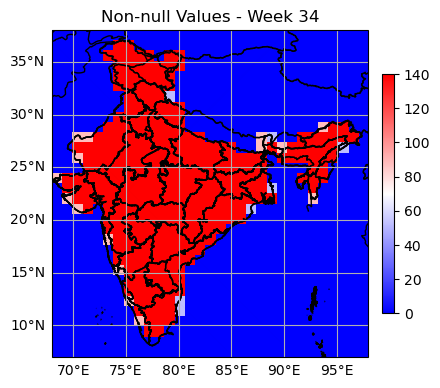

In [33]:
west, east, south, north = 68, 98, 7, 38
fig = plt.figure(figsize=(15,5))

# Plot for RPSS
ax1 = fig.add_subplot(1, 3, 1, projection=ccrs.PlateCarree())
ax1.set_extent([west, east, south, north], crs=ccrs.PlateCarree())
rpss_image = ax1.imshow(np.flip(missing_mat, axis=0), cmap='bwr', extent=[west, east, south, north])
ax1.set_title(f"Non-null Values - Week {week}")
ax1.add_feature(cf.BORDERS)
ax1.add_feature(cf.STATES)
gl = ax1.gridlines(draw_labels=True)
gl.top_labels = False
gl.right_labels = False
plt.colorbar(rpss_image, ax=ax1, fraction=0.035, pad=0.04)

plot(ax1, west, east, south, north)

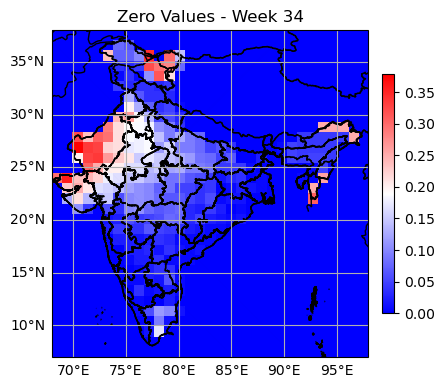

In [34]:
west, east, south, north = 68, 98, 7, 38
fig = plt.figure(figsize=(15,5))

# Plot for RPSS
ax1 = fig.add_subplot(1, 3, 1, projection=ccrs.PlateCarree())
ax1.set_extent([west, east, south, north], crs=ccrs.PlateCarree())
rpss_image = ax1.imshow(np.flip((140-nonz_mat)/140, axis=0), cmap='bwr', extent=[west, east, south, north])
ax1.set_title(f"Zero Values - Week {week}")
ax1.add_feature(cf.BORDERS)
ax1.add_feature(cf.STATES)
gl = ax1.gridlines(draw_labels=True)
gl.top_labels = False
gl.right_labels = False
plt.colorbar(rpss_image, ax=ax1, fraction=0.035, pad=0.04)

plot(ax1, west, east, south, north)